NASA POWER: Agroclimatology & Meteorological Data: NASA POWER provides accessible solar, meteorological, and climatology datasets used widely in agriculture. The datasets include temperature, humidity, radiation, and derived indicators that help estimate crop water use, growing‑season conditions, frost risk, and climate suitability for potential rotation crops.

In [4]:

!pip install -q pandas numpy matplotlib seaborn requests h5py xarray netCDF4 rasterio geopandas scipy


In [5]:

import os
import json
import requests
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime
from pathlib import Path

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


Cell 3 — تحديد مناطق الدراسة

In [6]:

regions = {
    "Mansoura": {
        "latitude": 31.04,
        "longitude": 31.38,
        "governorate": "Dakahlia",
        "climate_group": "Nile Delta",
        "crops": ["Rice", "Wheat"]
    },

    "Fayoum": {
        "latitude": 29.31,
        "longitude": 30.84,
        "governorate": "Fayoum",
        "climate_group": "Middle Egypt",
        "crops": ["Wheat", "Maize"]
    },

    "Ismailia": {
        "latitude": 30.60,
        "longitude": 32.27,
        "governorate": "Ismailia",
        "climate_group": "Eastern Egypt",
        "crops": ["Mango", "Wheat"]
    },

    "Luxor": {
        "latitude": 25.69,
        "longitude": 32.64,
        "governorate": "Luxor",
        "climate_group": "Upper Egypt",
        "crops": ["Sugarcane", "Wheat"]
    },

    "Marsa Matrouh": {
        "latitude": 31.35,
        "longitude": 27.24,
        "governorate": "Matrouh",
        "climate_group": "Mediterranean / Arid",
        "crops": ["Barley", "Olives"]
    }
}

regions_df = pd.DataFrame(regions).T

regions_df


,latitude,longitude,governorate,climate_group,crops
Mansoura,31.04,31.38,Dakahlia,Nile Delta,"[Rice, Wheat]"
Fayoum,29.31,30.84,Fayoum,Middle Egypt,"[Wheat, Maize]"
Ismailia,30.6,32.27,Ismailia,Eastern Egypt,"[Mango, Wheat]"
Luxor,25.69,32.64,Luxor,Upper Egypt,"[Sugarcane, Wheat]"
Marsa Matrouh,31.35,27.24,Matrouh,Mediterranean / Arid,"[Barley, Olives]"


In [7]:

START_DATE = "20200101"
END_DATE = "20251231"

start_year = 2020
end_year = 2025

print("Analysis period:", START_DATE, "to", END_DATE)
print("Number of regions:", len(regions))


Analysis period: 20200101 to 20251231
Number of regions: 5


In [8]:

POWER_URL = (
    "https://power.larc.nasa.gov/api/temporal/daily/point"
)

parameters = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS2M",
    "ALLSKY_SFC_SW_DWN"
]

def get_power_data(region_name, region_info):

    params = {
        "parameters": ",".join(parameters),
        "community": "AG",
        "longitude": region_info["longitude"],
        "latitude": region_info["latitude"],
        "start": START_DATE,
        "end": END_DATE,
        "format": "JSON",
        "time-standard": "UTC"
    }

    response = requests.get(
        POWER_URL,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    result = response.json()

    data = result["properties"]["parameter"]

    df = pd.DataFrame(data)

    df.index = pd.to_datetime(
        df.index,
        format="%Y%m%d"
    )

    df.index.name = "date"
    df = df.reset_index()

    df["region"] = region_name
    df["latitude"] = region_info["latitude"]
    df["longitude"] = region_info["longitude"]

    return df


print("NASA POWER function is ready!")


NASA POWER function is ready!


In [9]:

all_power_data = []

for region_name, region_info in regions.items():

    print(f"Downloading data for {region_name}...")

    try:
        region_data = get_power_data(
            region_name,
            region_info
        )

        all_power_data.append(region_data)

        print("Downloaded:", len(region_data), "rows")

    except Exception as e:
        print("Error:", region_name, e)


power_df = pd.concat(
    all_power_data,
    ignore_index=True
)

print("\nFinal shape:", power_df.shape)

power_df.head()


Downloaded: 2192 rows
Downloaded: 2192 rows
Downloaded: 2192 rows
Downloaded: 2192 rows
Downloaded: 2192 rows

Final shape: (10960, 11)


,date,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,region,latitude,longitude
0,2020-01-01,12.83,19.00,8.29,70.49,0.06,1.51,8.96,Mansoura,31.04,31.38
1,2020-01-02,12.14,18.65,7.46,64.72,0.94,3.51,9.08,Mansoura,31.04,31.38
2,2020-01-03,11.56,16.06,6.99,68.65,2.53,5.09,11.10,Mansoura,31.04,31.38
3,2020-01-04,12.95,17.18,10.84,77.82,3.95,3.42,6.84,Mansoura,31.04,31.38
4,2020-01-05,12.90,19.12,8.18,63.80,0.05,3.37,9.93,Mansoura,31.04,31.38


In [10]:

print("Shape:", power_df.shape)

print("\nData types:")
print(power_df.dtypes)

print("\nFirst rows:")
display(power_df.head())

print("\nLast rows:")
display(power_df.tail())

print("\nStatistical summary:")
display(power_df.describe(include="all"))

print("\nMissing values:")
display(power_df.isna().sum())

print("\nDuplicate rows:")
print(power_df.duplicated().sum())


Shape: (10960, 11)

Data types:
date                 datetime64[ns]
T2M                         float64
T2M_MAX                     float64
T2M_MIN                     float64
RH2M                        float64
PRECTOTCORR                 float64
WS2M                        float64
ALLSKY_SFC_SW_DWN           float64
region                       object
latitude                    float64
longitude                   float64
dtype: object

First rows:


,date,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,region,latitude,longitude
0,2020-01-01,12.83,19.00,8.29,70.49,0.06,1.51,8.96,Mansoura,31.04,31.38
1,2020-01-02,12.14,18.65,7.46,64.72,0.94,3.51,9.08,Mansoura,31.04,31.38
2,2020-01-03,11.56,16.06,6.99,68.65,2.53,5.09,11.10,Mansoura,31.04,31.38
3,2020-01-04,12.95,17.18,10.84,77.82,3.95,3.42,6.84,Mansoura,31.04,31.38
4,2020-01-05,12.90,19.12,8.18,63.80,0.05,3.37,9.93,Mansoura,31.04,31.38



Last rows:


,date,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,region,latitude,longitude
10955,2025-12-27,17.57,18.79,16.73,70.75,0.01,5.08,11.20,Marsa Matrouh,31.35,27.24
10956,2025-12-28,16.96,17.76,16.28,71.36,0.01,6.24,10.46,Marsa Matrouh,31.35,27.24
10957,2025-12-29,17.93,19.69,16.80,71.65,0.01,5.76,8.99,Marsa Matrouh,31.35,27.24
10958,2025-12-30,17.38,18.79,15.89,64.22,0.00,5.34,9.81,Marsa Matrouh,31.35,27.24
10959,2025-12-31,16.87,18.36,15.10,66.95,0.01,7.96,11.70,Marsa Matrouh,31.35,27.24



Statistical summary:


,date,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,region,latitude,longitude
count,10960,10960.000000,10960.000000,10960.000000,10960.000000,10960.000000,10960.000000,10960.000000,10960,10960.000000,10960.000000
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Mansoura,NaN,NaN
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2192,NaN,NaN
mean,2022-12-31 12:00:00,22.601010,29.269445,16.890683,53.760980,0.347973,3.266410,20.890803,NaN,29.598000,30.874000
min,2020-01-01 00:00:00,7.060000,11.230000,0.560000,7.500000,0.000000,0.540000,2.730000,NaN,25.690000,27.240000
25%,2021-07-01 18:00:00,16.740000,22.440000,11.887500,43.267500,0.000000,2.400000,15.300000,NaN,29.310000,30.840000
50%,2022-12-31 12:00:00,22.910000,28.690000,17.440000,55.960000,0.000000,3.090000,21.680000,NaN,30.600000,31.380000
75%,2024-07-01 06:00:00,28.270000,36.600000,22.070000,67.587500,0.010000,3.930000,26.830000,NaN,31.040000,32.270000
max,2025-12-31 00:00:00,38.710000,47.830000,30.740000,92.690000,332.990000,11.060000,31.310000,NaN,31.350000,32.640000



Missing values:


date                 0
T2M                  0
T2M_MAX              0
T2M_MIN              0
RH2M                 0
PRECTOTCORR          0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
region               0
latitude             0
longitude            0
dtype: int64


Duplicate rows:
0


In [11]:

power_df = power_df.copy()

# 1. Count records before cleaning
rows_before = len(power_df)

# 2. Replace NASA missing-value flag
power_df.replace([-999, -999.0], np.nan, inplace=True)

# 3. Count duplicates BEFORE removing them
duplicate_count = power_df.duplicated(
    subset=["date", "region"]
).sum()

# 4. Remove duplicate records
power_df.drop_duplicates(
    subset=["date", "region"],
    inplace=True
)

# 5. Count negative rainfall BEFORE handling it
negative_rainfall_count = (
    power_df["PRECTOTCORR"] < 0
).sum()

# 6. Replace negative rainfall with missing values
power_df.loc[
    power_df["PRECTOTCORR"] < 0,
    "PRECTOTCORR"
] = np.nan

# 7. Sort data
power_df.sort_values(
    ["region", "date"],
    inplace=True
)

power_df.reset_index(drop=True, inplace=True)

# 8. Cleaning summary
cleaning_summary = pd.DataFrame({
    "Metric": [
        "Rows before cleaning",
        "Duplicate records removed",
        "Negative rainfall values handled",
        "Rows after cleaning"
    ],
    "Count": [
        rows_before,
        duplicate_count,
        negative_rainfall_count,
        len(power_df)
    ]
})

display(cleaning_summary)


,Metric,Count
0,Rows before cleaning,10960
1,Duplicate records removed,0
2,Negative rainfall values handled,0
3,Rows after cleaning,10960


In [12]:

# ==========================================
# DATA VALIDATION
# ==========================================

validation_results = {}

# 1. Expected number of daily records
expected_days = len(
    pd.date_range(
        start=pd.to_datetime(START_DATE),
        end=pd.to_datetime(END_DATE),
        freq="D"
    )
)

region_counts = power_df.groupby("region").size()

validation_results["Expected days per region"] = expected_days
validation_results["Number of regions"] = power_df["region"].nunique()
validation_results["Total records"] = len(power_df)

print("Records per region:")
display(region_counts.rename("Actual Records").to_frame())

# 2. Duplicate check
validation_results["Remaining duplicates"] = (
    power_df.duplicated(["date", "region"]).sum()
)

# 3. Date range check
validation_results["Dates outside requested period"] = (
    (
        (power_df["date"] < pd.to_datetime(START_DATE)) |
        (power_df["date"] > pd.to_datetime(END_DATE))
    ).sum()
)

# 4. Physical range checks
validation_results["Humidity outside 0-100"] = (
    ((power_df["RH2M"] < 0) | (power_df["RH2M"] > 100))
    .sum()
)

validation_results["Negative rainfall"] = (
    (power_df["PRECTOTCORR"] < 0).sum()
)

validation_results["Negative wind speed"] = (
    (power_df["WS2M"] < 0).sum()
)

validation_results["Negative solar radiation"] = (
    (power_df["ALLSKY_SFC_SW_DWN"] < 0).sum()
)

# 5. Temperature consistency
validation_results["T2M_MAX below T2M_MIN"] = (
    (power_df["T2M_MAX"] < power_df["T2M_MIN"]).sum()
)

# 6. Missing values
validation_results["Total missing values"] = (
    power_df.isna().sum().sum()
)

# 7. Check whether each region has the expected number of records
validation_results["Regions with unexpected record count"] = (
    (region_counts != expected_days).sum()
)

# Display validation report
validation_report = pd.DataFrame(
    list(validation_results.items()),
    columns=["Validation Check", "Result"]
)

display(validation_report)


Records per region:


,Actual Records
region,
Fayoum,2192
Ismailia,2192
Luxor,2192
Mansoura,2192
Marsa Matrouh,2192


,Validation Check,Result
0,Expected days per region,2192
1,Number of regions,5
2,Total records,10960
3,Remaining duplicates,0
4,Dates outside requested period,0
5,Humidity outside 0-100,0
6,Negative rainfall,0
7,Negative wind speed,0
8,Negative solar radiation,0
9,T2M_MAX below T2M_MIN,0


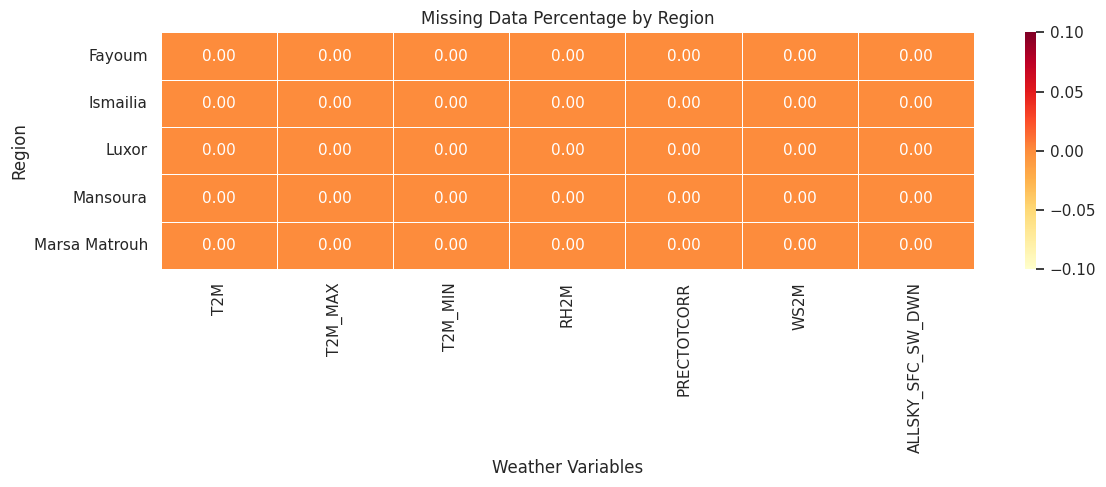

In [13]:

missing_percentage = (
    power_df.groupby("region")[parameters]
    .apply(lambda x: x.isna().mean() * 100)
)

plt.figure(figsize=(12, 5))

sns.heatmap(
    missing_percentage,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title("Missing Data Percentage by Region")
plt.xlabel("Weather Variables")
plt.ylabel("Region")
plt.tight_layout()
plt.show()


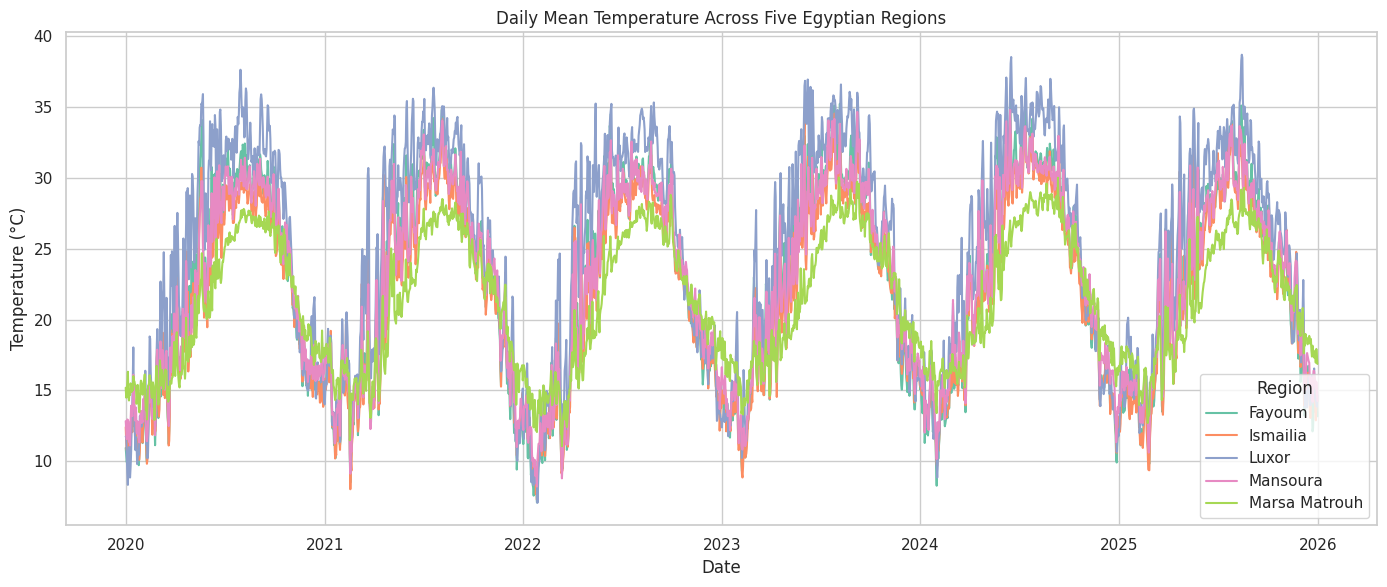

In [14]:

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=power_df,
    x="date",
    y="T2M",
    hue="region",
    errorbar=None
)

plt.title("Daily Mean Temperature Across Five Egyptian Regions")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend(title="Region")
plt.tight_layout()
plt.show()


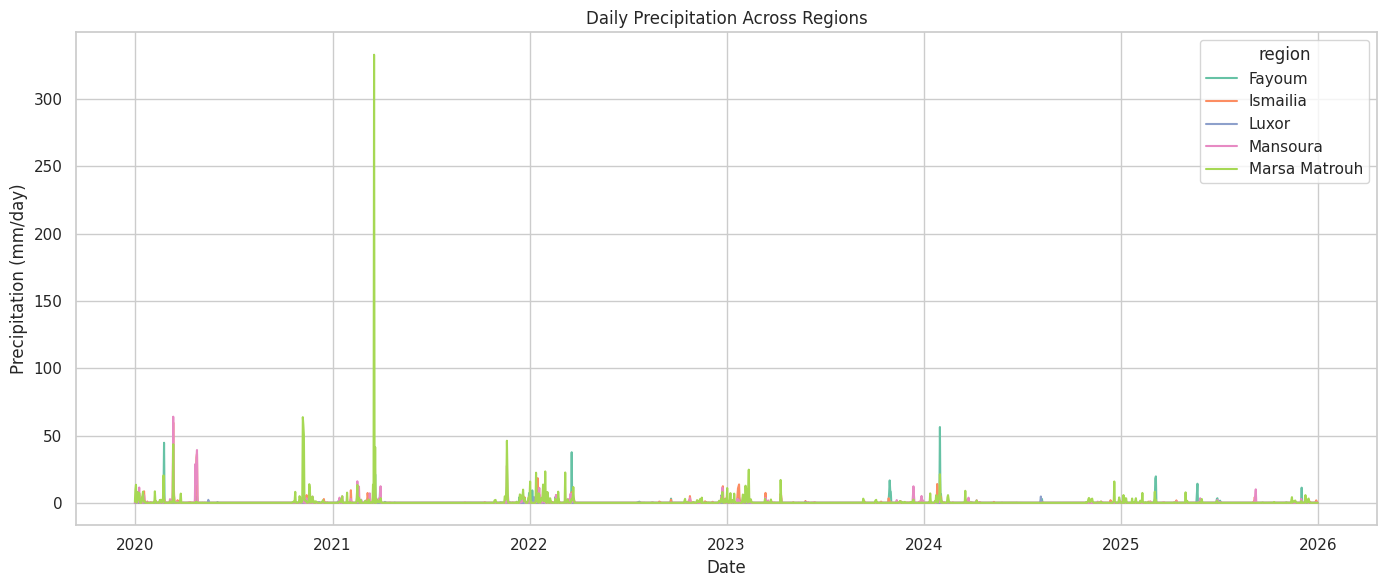

In [15]:

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=power_df,
    x="date",
    y="PRECTOTCORR",
    hue="region",
    errorbar=None
)

plt.title("Daily Precipitation Across Regions")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm/day)")
plt.tight_layout()
plt.show()


In [17]:

power_df = power_df.sort_values(
    ["region", "date"]
).copy()

# Rainfall accumulated over the last 7 days
power_df["rainfall_7d"] = (
    power_df.groupby("region")["PRECTOTCORR"]
    .transform(lambda x: x.rolling(7, min_periods=7).sum())
)

# Average temperature over the last 7 days
power_df["temperature_7d_avg"] = (
    power_df.groupby("region")["T2M"]
    .transform(lambda x: x.rolling(7, min_periods=7).mean())
)

# Average relative humidity over the last 7 days
power_df["humidity_7d_avg"] = (
    power_df.groupby("region")["RH2M"]
    .transform(lambda x: x.rolling(7, min_periods=7).mean())
)

# Temperature difference between max and min
power_df["daily_temp_range"] = (
    power_df["T2M_MAX"] - power_df["T2M_MIN"]
)

display(power_df.head(10))


,date,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,region,latitude,longitude,rainfall_7d,temperature_7d_avg,humidity_7d_avg,daily_temp_range
0,2020-01-01,10.94,17.21,6.30,62.26,0.00,2.00,10.96,Fayoum,29.31,30.84,NaN,NaN,NaN,10.91
1,2020-01-02,10.38,15.79,5.94,63.20,0.53,2.98,11.64,Fayoum,29.31,30.84,NaN,NaN,NaN,9.85
2,2020-01-03,9.93,15.56,5.23,67.06,0.14,4.23,11.76,Fayoum,29.31,30.84,NaN,NaN,NaN,10.33
3,2020-01-04,10.37,16.61,6.06,67.52,0.12,3.54,12.99,Fayoum,29.31,30.84,NaN,NaN,NaN,10.55
4,2020-01-05,9.76,16.83,3.75,66.83,0.01,2.45,13.68,Fayoum,29.31,30.84,NaN,NaN,NaN,13.08
5,2020-01-06,10.69,17.57,4.48,63.82,0.08,4.54,12.32,Fayoum,29.31,30.84,NaN,NaN,NaN,13.09
6,2020-01-07,10.13,15.15,6.02,65.52,0.04,4.05,11.18,Fayoum,29.31,30.84,0.92,10.314286,65.172857,9.13
7,2020-01-08,9.51,16.13,4.05,67.90,0.04,3.87,13.73,Fayoum,29.31,30.84,0.96,10.110000,65.978571,12.08
8,2020-01-09,9.92,14.87,4.61,76.62,2.49,3.98,12.02,Fayoum,29.31,30.84,2.92,10.044286,67.895714,10.26
9,2020-01-10,11.57,17.14,7.11,76.08,2.41,3.70,11.72,Fayoum,29.31,30.84,5.19,10.278571,69.184286,10.03


In [31]:

# ==========================================
# ROLLING FEATURES VALIDATION
# ==========================================

rolling_features = [
    "rainfall_7d",
    "temperature_7d_avg",
    "humidity_7d_avg"
]

# Check missing values per region
rolling_missing = (
    power_df.groupby("region")[rolling_features]
    .apply(lambda x: x.isna().sum())
)

print("Missing values per region:")
display(rolling_missing)

# Check missing values distribution
print("\nExpected missing values per feature:")
display(power_df[rolling_features].isna().sum())

# Verify the expected 6 initial missing days
expected_missing = 6

for region, group in power_df.groupby("region"):
    first_rows = group.head(expected_missing)

    assert first_rows[rolling_features].isna().all().all(), (
        f"Unexpected missing values in {region}"
    )

print("\nRolling feature validation completed!")


Missing values per region:


,rainfall_7d,temperature_7d_avg,humidity_7d_avg
region,,,
Fayoum,6,6,6
Ismailia,6,6,6
Luxor,6,6,6
Mansoura,6,6,6
Marsa Matrouh,6,6,6



Expected missing values per feature:


rainfall_7d           30
temperature_7d_avg    30
humidity_7d_avg       30
dtype: int64


Rolling feature validation completed!


In [49]:
# Remove rolling features to keep the dataset simple
rolling_features = [
    "rainfall_7d",
    "temperature_7d_avg",
    "humidity_7d_avg"
]

power_df.drop(columns=rolling_features, inplace=True)

# Export simplified daily dataset
power_df.to_csv(
    "SpaceSoil_Data/nasa_power_cleaned.csv",
    index=False
)

print("Final Daily Dataset:", power_df.shape)
print("Missing Values:", power_df.isnull().sum().sum())
print("NASA POWER dataset is ready!")

KeyError: "['rainfall_7d', 'temperature_7d_avg', 'humidity_7d_avg'] not found in axis"

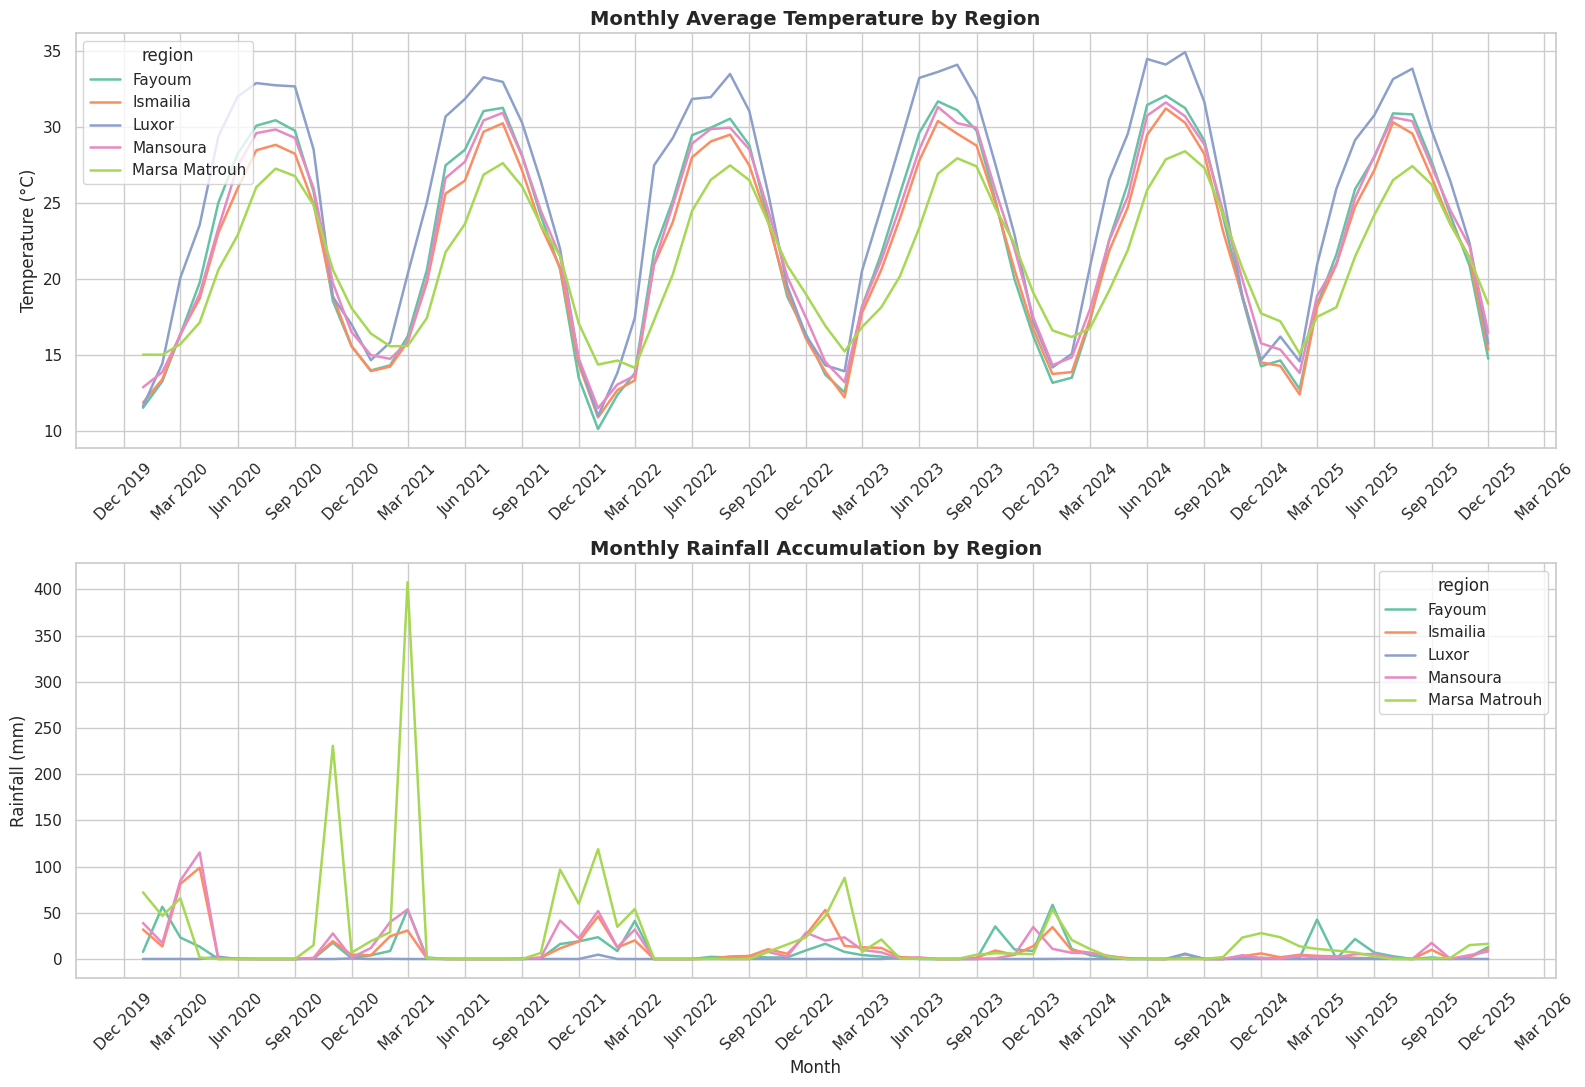

In [40]:

import matplotlib.dates as mdates

# Convert year_month to datetime
monthly_df["year_month"] = pd.to_datetime(
    monthly_df["year_month"]
)

# Sort data chronologically
monthly_df = monthly_df.sort_values(
    ["region", "year_month"]
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(16, 11)
)

# 1. Monthly Average Temperature
sns.lineplot(
    data=monthly_df,
    x="year_month",
    y="T2M",
    hue="region",
    ax=axes[0],
    linewidth=1.8
)

axes[0].set_title(
    "Monthly Average Temperature by Region",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Temperature (°C)")
axes[0].set_xlabel("")

# Show one label every 3 months
axes[0].xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
axes[0].xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)
axes[0].tick_params(axis="x", rotation=45)


# 2. Monthly Rainfall Accumulation
sns.lineplot(
    data=monthly_df,
    x="year_month",
    y="PRECTOTCORR",
    hue="region",
    ax=axes[1],
    linewidth=1.8
)

axes[1].set_title(
    "Monthly Rainfall Accumulation by Region",
    fontsize=14,
    fontweight="bold"
)
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Rainfall (mm)")

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(interval=3)
)
axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)
axes[1].tick_params(axis="x", rotation=45)

# Improve layout
plt.tight_layout()
plt.show()


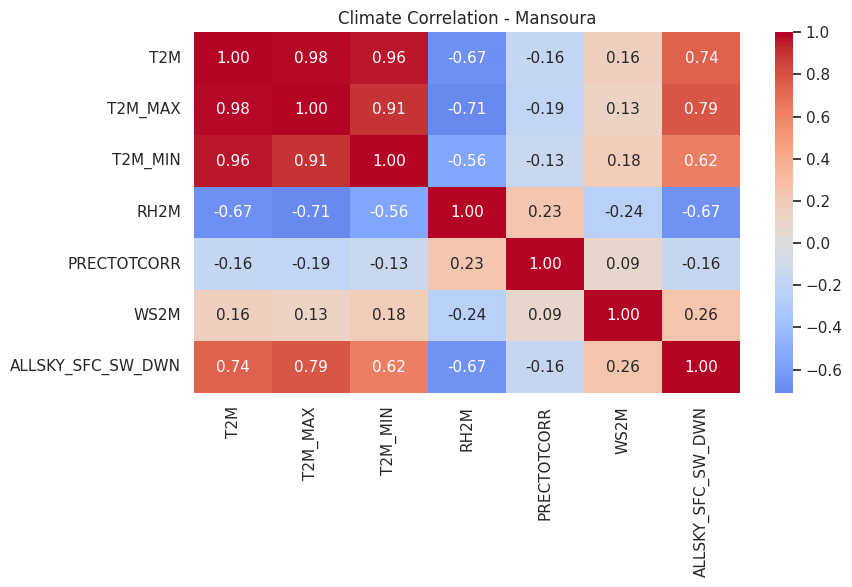

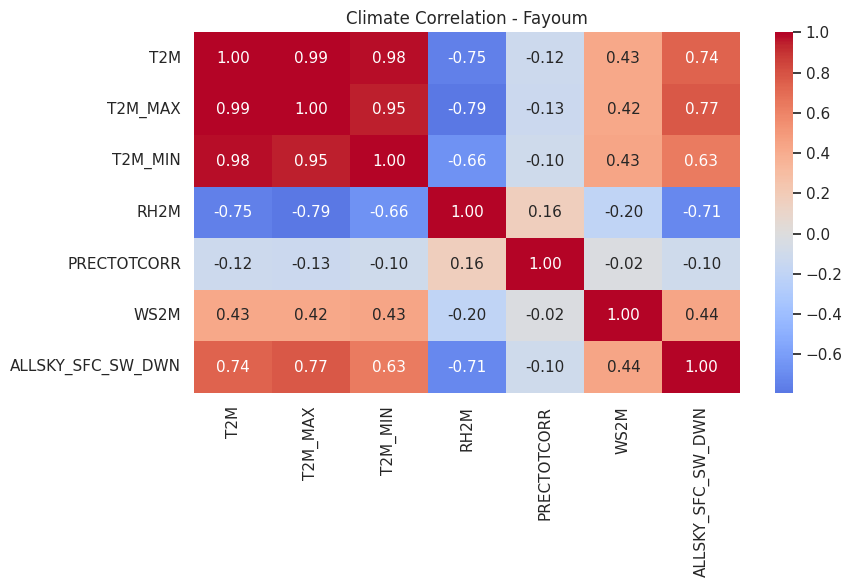

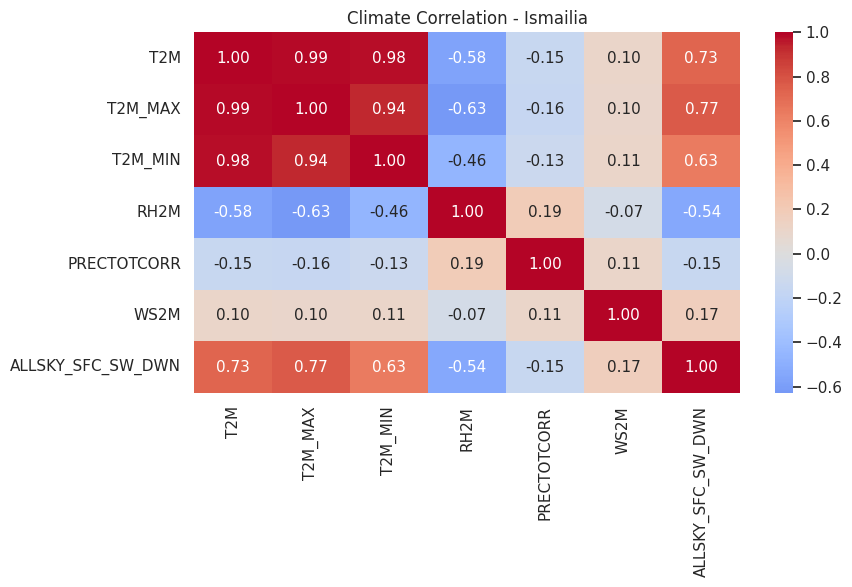

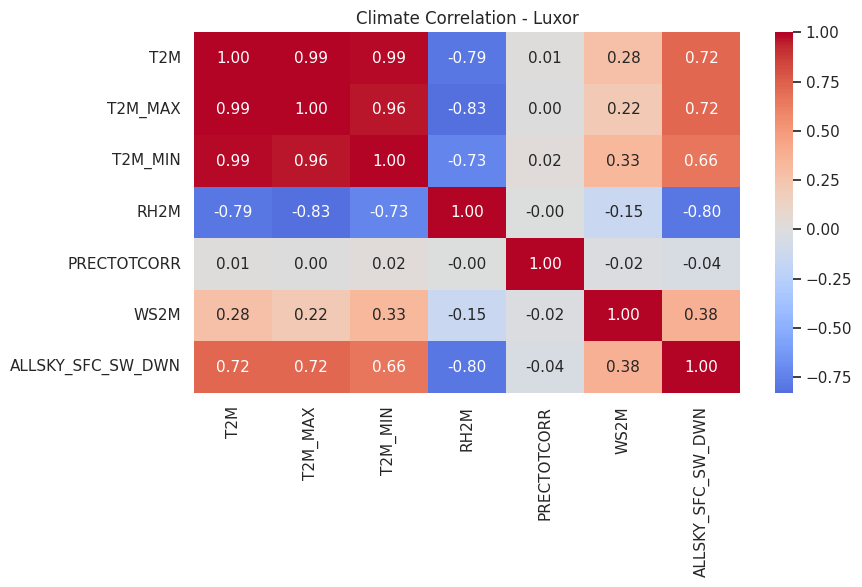

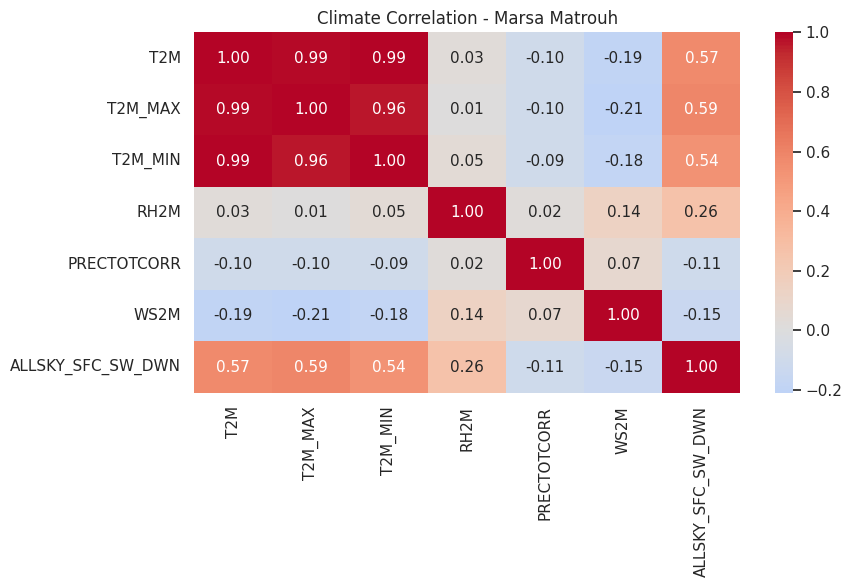

In [41]:

climate_variables = [
    "T2M",
    "T2M_MAX",
    "T2M_MIN",
    "RH2M",
    "PRECTOTCORR",
    "WS2M",
    "ALLSKY_SFC_SW_DWN"
]

for region_name in regions:

    region_data = power_df[
        power_df["region"] == region_name
    ]

    plt.figure(figsize=(9, 6))

    correlation = region_data[
        climate_variables
    ].corr()

    sns.heatmap(
        correlation,
        annot=True,
        cmap="coolwarm",
        center=0,
        fmt=".2f"
    )

    plt.title(f"Climate Correlation - {region_name}")
    plt.tight_layout()
    plt.show()


In [52]:

import json
import os

# Create output directory
os.makedirs("SpaceSoil_Data", exist_ok=True)

# Dataset metadata
metadata = {
    "dataset_name": "NASA_POWER_Egypt_Agricultural_Weather",
    "source": "NASA POWER API",
    "community": "AG",
    "temporal_resolution": "Daily",
    "start_date": str(power_df["date"].min().date()),
    "end_date": str(power_df["date"].max().date()),
    "number_of_regions": int(power_df["region"].nunique()),
    "total_records": int(len(power_df)),
    "records_per_region": {
        str(k): int(v)
        for k, v in power_df.groupby("region").size().items()
    },
    "variables": {
        "T2M": {
            "description": "Daily mean temperature at 2 meters",
            "unit": "°C"
        },
        "T2M_MAX": {
            "description": "Daily maximum temperature at 2 meters",
            "unit": "°C"
        },
        "RH2M": {
            "description": "Relative humidity at 2 meters",
            "unit": "%"
        },
        "PRECTOTCORR": {
            "description": "Corrected precipitation",
            "unit": "mm/day"
        },
        "WS2M": {
            "description": "Wind speed at 2 meters",
            "unit": "m/s"
        },
        "ALLSKY_SFC_SW_DWN": {
            "description": "All-sky surface shortwave downward radiation",
            "unit": "kWh/m2/day"
        }
    },
    "preprocessing": [
        "NASA missing-value flags converted to NaN",
        "Duplicate records checked and removed if present",
        "Negative rainfall values handled",
        "Data sorted by region and date",
        "Data validation performed"
    ],
    "limitations": [
        "No direct crop health labels",
        "No direct soil moisture measurements",
        "Weather estimates are not field-level sensor measurements"
    ]
}

# Save metadata
metadata_path = "SpaceSoil_Data/nasa_power_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved successfully!")
print("File:", metadata_path)


Metadata saved successfully!
File: SpaceSoil_Data/nasa_power_metadata.json


In [53]:

# ==========================================
# FINAL DATA EXPORT
# ==========================================

output_dir = "SpaceSoil_Data"
os.makedirs(output_dir, exist_ok=True)

# Save daily dataset
daily_path = os.path.join(
    output_dir,
    "nasa_power_cleaned.csv"
)

power_df.to_csv(daily_path, index=False)

# Save monthly dataset
monthly_path = os.path.join(
    output_dir,
    "nasa_power_monthly.csv"
)

monthly_df.to_csv(monthly_path, index=False)

print("All datasets exported successfully!")

print("\nExported files:")
print(daily_path)
print(monthly_path)
print(metadata_path)


All datasets exported successfully!

Exported files:
SpaceSoil_Data/nasa_power_cleaned.csv
SpaceSoil_Data/nasa_power_monthly.csv
SpaceSoil_Data/nasa_power_metadata.json


In [55]:
daily_check = pd.read_csv(daily_path, parse_dates=["date"])
monthly_check = pd.read_csv(monthly_path)

with open(metadata_path, "r") as f:
    metadata_check = json.load(f)

In [56]:
os.makedirs("SpaceSoil_Data", exist_ok=True)

power_df.to_csv(
    "SpaceSoil_Data/nasa_power_cleaned.csv",
    index=False
)

monthly_df.to_csv(
    "SpaceSoil_Data/nasa_power_monthly.csv",
    index=False
)

print("Files saved successfully!")


Files saved successfully!


In [57]:
print("Daily dataset:", daily_check.shape)
print("Monthly dataset:", monthly_check.shape)

print("\nDaily regions:")
print(daily_check["region"].unique())

print("\nMetadata:")
print(metadata_check["dataset_name"])

Daily dataset: (10960, 13)
Monthly dataset: (360, 8)

Daily regions:
['Fayoum' 'Ismailia' 'Luxor' 'Mansoura' 'Marsa Matrouh']

Metadata:
NASA_POWER_Egypt_Agricultural_Weather


In [46]:
print("Daily Dataset Columns:")
for i, col in enumerate(daily_check.columns, 1):
    print(i, "-", col)

print("\nMonthly Dataset Columns:")
for i, col in enumerate(monthly_check.columns, 1):
    print(i, "-", col)

Daily Dataset Columns:
1 - date
2 - T2M
3 - T2M_MAX
4 - T2M_MIN
5 - RH2M
6 - PRECTOTCORR
7 - WS2M
8 - ALLSKY_SFC_SW_DWN
9 - region
10 - latitude
11 - longitude
12 - rainfall_7d
13 - temperature_7d_avg
14 - humidity_7d_avg
15 - daily_temp_range
16 - year_month

Monthly Dataset Columns:
1 - region
2 - year_month
3 - T2M
4 - T2M_MAX
5 - RH2M
6 - PRECTOTCORR
7 - WS2M
8 - ALLSKY_SFC_SW_DWN


In [51]:

# Update and reload the final Daily Dataset

rolling_features = [
    "rainfall_7d",
    "temperature_7d_avg",
    "humidity_7d_avg"
]

# Remove rolling features if they still exist
power_df.drop(
    columns=rolling_features,
    errors="ignore",
    inplace=True
)

# Save updated dataset
power_df.to_csv(daily_path, index=False)

# Reload the updated file
daily_check = pd.read_csv(
    daily_path,
    parse_dates=["date"]
)

# Final verification
print("Daily Dataset Shape:", daily_check.shape)

print("\nRemaining Columns:")
print(daily_check.columns.tolist())

print("\nMissing Values:")
print(daily_check.isna().sum())

print("\nTotal Missing Values:",
      daily_check.isna().sum().sum())


Daily Dataset Shape: (10960, 13)

Remaining Columns:
['date', 'T2M', 'T2M_MAX', 'T2M_MIN', 'RH2M', 'PRECTOTCORR', 'WS2M', 'ALLSKY_SFC_SW_DWN', 'region', 'latitude', 'longitude', 'daily_temp_range', 'year_month']

Missing Values:
date                 0
T2M                  0
T2M_MAX              0
T2M_MIN              0
RH2M                 0
PRECTOTCORR          0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
region               0
latitude             0
longitude            0
daily_temp_range     0
year_month           0
dtype: int64

Total Missing Values: 0



# NASA POWER Dataset — SpaceSoil

## 1. Project Overview
NASA POWER data was collected and processed to support the SpaceSoil project.

The dataset provides daily meteorological and solar radiation information for five different agricultural regions in Egypt.

The main goal is to analyze weather conditions and support agricultural monitoring, irrigation decisions, and weather-based alerts.

## 2. Data Source
- Source: NASA POWER
- API: Daily Point API
- Community: AG (Agroclimatology)
- Temporal Resolution: Daily
- Study Period: 2020-01-01 to 2025-12-31

## 3. Study Locations
The dataset covers five Egyptian regions:

1. Mansoura
2. Fayoum
3. Ismailia
4. Luxor
5. Marsa Matrouh

Each region contains 2,192 daily observations.

## 4. Original Variables

| Variable | Description |
|---|---|
| T2M | Daily mean temperature at 2 meters |
| T2M_MAX | Daily maximum temperature |
| T2M_MIN | Daily minimum temperature |
| RH2M | Relative humidity |
| PRECTOTCORR | Corrected precipitation |
| WS2M | Wind speed at 2 meters |
| ALLSKY_SFC_SW_DWN | All-sky surface solar radiation |

## 5. Data Preprocessing

The following preprocessing operations were performed:

- Converted NASA missing-value flags (-999) to NaN.
- Checked and removed duplicate records.
- Checked negative rainfall values.
- Sorted records by region and date.
- Added geographic coordinates (latitude and longitude).
- Created additional temporal features.

## 6. Feature Engineering

Three additional features were initially created using rolling calculations but were removed from the final dataset to avoid unnecessary missing values.

The retained engineered features are:

- daily_temp_range: Difference between daily maximum and minimum temperature.
- year_month: Year and month extracted from the observation date.

## 7. Exploratory Data Analysis (EDA)

The analysis included:

- Temperature trends across the five regions.
- Monthly rainfall accumulation.
- Monthly average temperature comparisons.
- Regional weather pattern analysis.
- Missing-value and duplicate detection.

## 8. Data Validation Results

- Total daily records: 10,960
- Number of regions: 5
- Records per region: 2,192
- Duplicate records: 0
- Missing values in final daily dataset: 0
- Missing values in monthly dataset: 0

All final dataset validation checks were completed.

## 9. Final Dataset Structure

### Daily Dataset
- Records: 10,960
- Features: 13

### Monthly Dataset
- Records: 360
- Features: 8

## 10. Exported Files

The final datasets were exported as:

- nasa_power_cleaned.csv
- nasa_power_monthly.csv
- nasa_power_metadata.json

## 11. Potential Applications in SpaceSoil

NASA POWER data can support the following features:

1. Weather monitoring for different agricultural regions.
2. Rainfall tracking and weather alerts.
3. Temperature monitoring and heat-stress warnings.
4. Relative humidity monitoring.
5. Supporting irrigation-related recommendations.
6. Comparing seasonal weather conditions.
7. Providing meteorological inputs for future Machine Learning models.

## 12. Dataset Limitations

- NASA POWER provides gridded weather estimates, not direct farm-level sensor measurements.
- The dataset does not directly measure soil moisture.
- It does not contain crop health labels or actual crop yield.
- Crop-specific recommendations require additional agricultural information.
- Soil moisture analysis will be supported by integrating NASA SMAP data.

## 13. Conclusion

The NASA POWER dataset has been collected, explored, cleaned, validated, and exported successfully.

It provides a meteorological foundation for SpaceSoil and can be integrated with other environmental datasets to develop an intelligent agricultural monitoring and decision-support system.
